In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import random
import seaborn as sns
from collections import Counter
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from langdetect import detect, DetectorFactory

from src.features import limpiar_features_no_necesarias, multi_binarizer_format, multi_binarizer_genre, transformar_target_a_estrellas, es_parte_de_saga, normalize_format, extraer_generos_libro, detectar_language_code, one_hot_language, generar_embeddings_pca, primer_tiene_role_vacio, extraer_autor_principal
from src.graficos import plot_boxplot_rating_por_genero, plot_generos_mas_frecuentes, plot_rating, plot_rating_por_genero, plot_stars, plot_boxplot_rating, plot_cantidad_generos_por_libro, plot_boxplot_rating_por_formato, plot_boxplot_rating_por_is_series, plot_scatter_rating_por_num_pages, plot_scatter_rating_por_publication_year, plot_boxplot_rating_por_autor_frecuent, plot_correlacion_features, plot_boxplot_rating_por_cant_generos, plot_stars_subplots, plot_ratings_subplots
from src.utils import fusionar_libros
from src.splitting import split_estratificado_autor

# 1. Comenzamos por filtrar el dataset:
DISCLAIMER: el dataset es muy pesado y toma mucho tiempo para correr. Adjuntamos el dataset original, en caso de que esta seccion quiera ser corrida, pero aparte adjuntamos un dataset intermedio con el primer filtrado. En caso de usar este segundo dataset, saltar directamente a la segunda seccion. 

## 1.1 Sacamos las muestras de paises non-US:
Analizando brevemente el dataset, nos damos cuenta de que la gran mayoria de libros son de Estados Unidos, y unos pocos de otros paises. Para eliminar ruido, decidimos predecir el rating unicamente de los libros marcados con la etiqueta US. 

In [ ]:
chunks = pd.read_json("goodreads_books.json", lines=True, chunksize=100_000)

us_list = []
for chunk in chunks:
    us_list.append(chunk[chunk["country_code"] == "US"])

df_us = pd.concat(us_list, ignore_index=True)
print(df_us.shape)


## 1.2 Nos quedamos nomas con los libros que son en ingles:

De los libros marcados con la etiqueta US, varios tienen diferentes idiomas: tanto variantes de ingles como otros idiomas (frances, aleman...). Decidimos basar nuestro modelo de machine learning unicamente en los libros escritos en ingles. 

Consideramos los libros en ingles los que tienen "languade_code" = ["en", "eng", "en-US", "en-GB", "en-CA", "enm", "ang", "sco", "gem"]

Las ultimas 4 opciones son ingles, pero antiguos. Esto podria llegar a afectar el rating del libro, por ejemplo podria costar mas entenderlo, impactando negativamente en el rating.

Tambien nos quedamos con las muestras con ese valor NaN, porque aun no podemos decidir si descartarlos o no.

In [ ]:
valid_langs = {"en", "eng", "en-us", "en-gb", "en-ca", "enm", "ang", "sco", "gem"}
lang = df_us["language_code"].fillna("").str.strip().str.lower()
df_us_eng = df_us[lang.isin(valid_langs) | (lang == "")]

Una vez hecho este filtrado, lo guardamos en un json, para luego poder cargar menos muestras.

In [ ]:
output_path = "goodreads_us_english.json"
chunk_size = 10000
with open(output_path, "w", encoding="utf-8") as f:
    for start in range(0, len(df_us_eng), chunk_size):
        chunk = df_us_eng.iloc[start:start + chunk_size]
        records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
        for record in records:
            json.dump(record, f, ensure_ascii=False)
            f.write("\n")
print("Guardado en", output_path)

Abrimos el nuevo archivo que acabamos de crear, trabajamos sobre ese:

In [2]:
chunks2 = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)

chunk_list = []
for chunk in chunks2:
    chunk_list.append(chunk)

df_us_en = pd.concat(chunk_list, ignore_index=True)
print(df_us_en.shape)

(1925872, 29)


# 2. Analizamos features (EDA):

In [ ]:
df_us_en.to_pickle("checkpoint_fusion1.pkl")

## 2.1 Analizamos el target

In [3]:
df_us_en["average_rating"] = pd.to_numeric(df_us_en["average_rating"], errors='coerce')
print(f"Nan en average_rating: {df_us_en["average_rating"].isna().sum()}")
print(f"Max de average_rating: {df_us_en["average_rating"].max()}")
print(f"Min de average_rating: {df_us_en["average_rating"].min()}")

Nan en average_rating: 6
Max de average_rating: 5.0
Min de average_rating: 0.0


En el dataset hay 6 filas que tienen Nan en el target, las eliminamos. Notamos aparte que no hay outliers. Aparte, el rating efectivamente toma valores entre 0 y 5. 
Para el entrenamiento con regresion, vamos a usar la feature "average_rating", pero necesitamos crear el target para clasificacion, es decir transformar el rating continuo en una cantidad discreta de estrellas. <br> Para esto, decidimos redondear el rating formando 6 clases diferentes:
- < 0.5: 0 estrellas
- [0.5, 1.5): 1 estrella
- [1.5, 2.5): 2 estrellas
- [2.5, 3.5): 3 estrellas
- [3.5, 4.5): 4 estrellas
- \>= 4.5: 5 estrellas

In [4]:
df_us_en = df_us_en.dropna(subset=["average_rating"]) #Eliminamos todas las muetsras que tienen avergae_rating = NaN o = None
target_regresion = df_us_en["average_rating"]
df_us_en["estrellas"] = transformar_target_a_estrellas(target_regresion)

In [5]:
df_us_en["average_rating"].describe()

count    1.925866e+06
mean     3.885112e+00
std      5.304168e-01
min      0.000000e+00
25%      3.650000e+00
50%      3.920000e+00
75%      4.170000e+00
max      5.000000e+00
Name: average_rating, dtype: float64

In [16]:
df_us_en["estrellas"].value_counts(normalize=True).sort_index()

estrellas
0    0.002874
1    0.001938
2    0.010903
3    0.142532
4    0.765295
5    0.076458
Name: proportion, dtype: float64

In [8]:
df_us_en.to_pickle("checkpoint_fusion2.pkl")

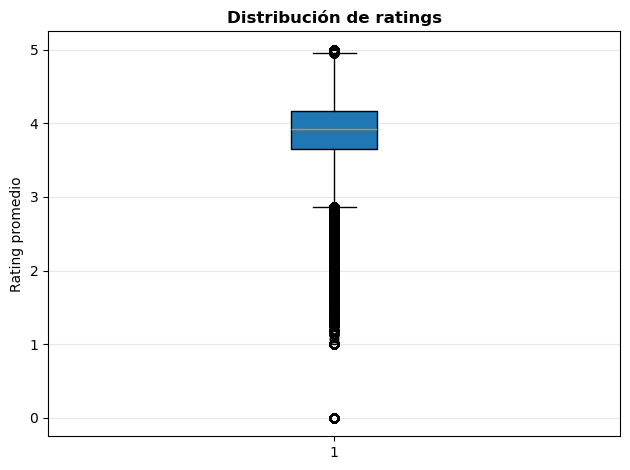

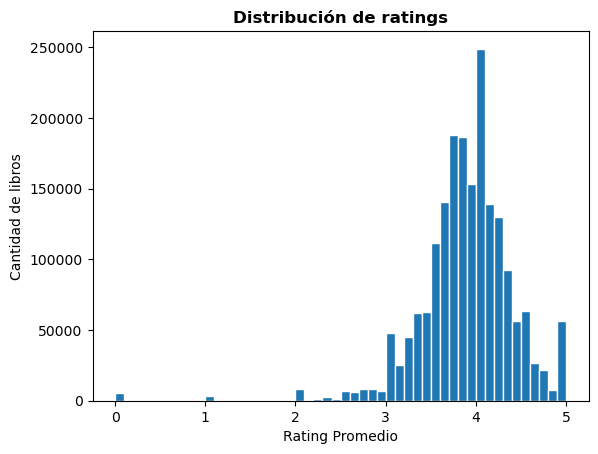

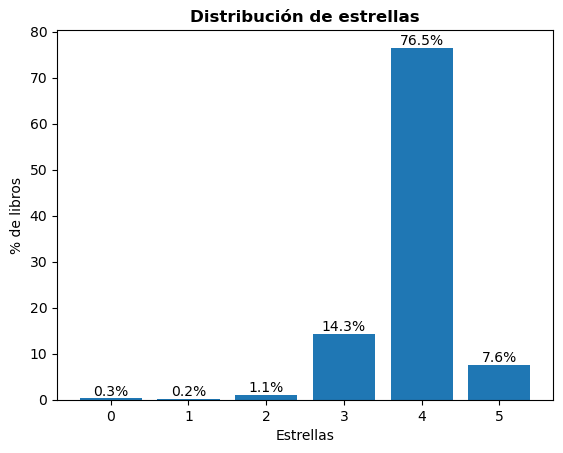

In [18]:
plot_boxplot_rating(df_us_en)
plot_rating(df_us_en)
plot_stars(df_us_en)

La mayoria de los ratings se encuentra entre 3.5 y 4.5. Este desbalance se hace mas presente al pasar el rating a estrellas. Vamos a tener que tener esto presente al momento de realizar los modelos con clasificacion. 

## 2.2 ¿El formato del libro tiene alguna relacion con el rating?

Al imprimir algunos valores de format, nos damos cuenta que un mismo formato esta escrito de diferentes maneras. Para arreglar esto aplicamos una funcion para reagrupar los formatos similares, o con diferentes redacciones. De esta manera no nos vamos a encontrar con cientos de features al aplicar one hot encoding de esta feature. 

In [6]:
df_us_en["format"].value_counts().head(25)

format
Paperback                648488
                         583911
Hardcover                278436
ebook                    172402
Kindle Edition           119245
Audio CD                  29959
Mass Market Paperback     29919
Audiobook                 15911
Audible Audio             10576
Audio                      8289
Unknown Binding            7527
Board Book                 4179
Library Binding            1525
Spiral-bound               1313
Audio Cassette             1115
paperback                  1022
Leather Bound               934
Board book                  892
MP3 CD                      846
Trade Paperback             630
Nook                        516
Chapbook                    358
Comic                       329
Novelty Book                271
paper                       259
Name: count, dtype: int64

In [ ]:
mixed = df_us_en["format"].str.contains("paperback.*ebook|ebook.*paperback|kindle.*paperback|paperback.*kindle", case=False, na=False)
print(mixed.sum())

224


Hay 224 libros que tienen mas de un formato a la vez, es una cantidad muy chica. 

In [7]:
#Le aplico la funcion para reagrupar:
if "format_group" not in df_us_en.columns:
    df_us_en["format_group"] = df_us_en["format"].apply(normalize_format)
df_us_en = df_us_en.drop(columns = ["format"]) 

print(df_us_en["format_group"].value_counts())

format_group
PAPERBACK    683447
UNKNOWN      591450
EBOOK        293266
HARDCOVER    281921
AUDIO         67250
OTHER          7742
COMIC           790
Name: count, dtype: int64


In [25]:
df_us_en["format_group"].value_counts(normalize=True) * 100

format_group
PAPERBACK    35.487775
UNKNOWN      30.710859
EBOOK        15.227747
HARDCOVER    14.638661
AUDIO         3.491936
OTHER         0.402001
COMIC         0.041021
Name: proportion, dtype: float64

Aproximadamente el 99.59% de las muestars quedaron clasificadas en categorias concretas. Hay muchos UNKNOWNS, que significa que el usuario no completo la informacion de esta categoria.

In [8]:
df_us_en.groupby("format_group")["average_rating"].agg(["count", "mean", "std"])

,count,mean,std
format_group,,,
AUDIO,67250,3.904904,0.326185
COMIC,790,3.891291,0.447508
EBOOK,293266,3.910180,0.530976
HARDCOVER,281921,3.836821,0.522361
OTHER,7742,3.847796,0.610235
PAPERBACK,683447,3.883242,0.507260
UNKNOWN,591450,3.896092,0.574507


Una vez realizado el agrupamiento, obtenemos 7 formatos diferentes, un numero muchisimo mas razonable para aplicar one hot encoding. 

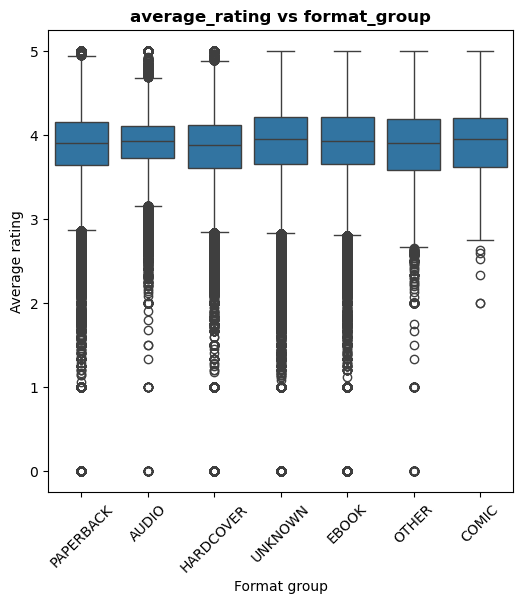

In [28]:
plot_boxplot_rating_por_formato(df_us_en)

Visualmente todas las lineas (medianas) quedaron casi a la misma altura. Esto sugiere que el rating de los libros es muy parecido independientemente del formato. Ademas, las cajas tienen tamaños similares, lo que indica que la dispersion de los ratings tambien es parecida.

Ahora, como la cantidad de muestras por categoria es muy significativa, tambien hay que analizar los valores estadisitcos (de la tabla de arriba):

En cuanto al mean --> La diferencia entre el mas alto y el mas bajo es: 3.910 - 3.837 = 0.073. Entonces, si bien existen pequeñas diferencias entre categorias, los valores medios de average_rating son muy similares para todos los formatos que estamos analizando. Esto sugiere que el formato de publicacion no presenta una relacion fuerte con la valoracion promedio de los libros.

En cuanto al std --> Los audiolibros tienen una dispersion bastante menor. Esto podria indicar que los audiolibros suelen recibir ratings mas consistentes, o que hay menos titulos de muy baja valoración dentro de AUDIO.

In [11]:
df_us_en.to_pickle("checkpoint_fusion3.pkl")

## 2.3 Analizamos la feature "series"

In [ ]:
df_us_en["series"].str.len().value_counts().sort_index()

series
0    1310737
1     563599
2      40949
3       7358
4       3223
Name: count, dtype: int64

La feature "series" contiene una lista. Si la lista esta vacia el libro no es parte de una saga. La tabla de arriba indica el largo de la lista, que corresponde a la cantidad de libros que tiene la saga.

In [9]:
#is_series: feature binaria, true si es parte de una saga
df_us_en["is_series"] = df_us_en["series"].apply(es_parte_de_saga)
df_us_en = df_us_en.drop(columns = ["series"]) 

Creamos la feature is_series, que tiene "true" si el libro es parte de una saga (es decir el largo de la lista de la feature "series" es mayor a 0), y "false" sino.

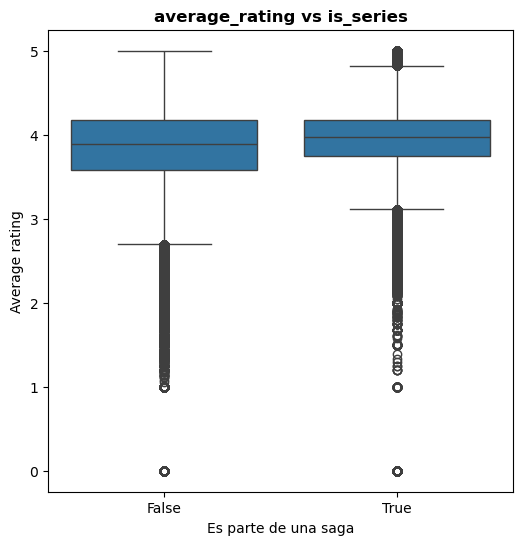

In [31]:
plot_boxplot_rating_por_is_series(df_us_en)

Los libros que pertenecen a una saga tienen ratings ligeramente mas altos --> La mediana de is_series = True esta un poco por encima de la de is_series = False

In [32]:
df_us_en.groupby("is_series")["average_rating"].agg(["count", "mean", "median", "std"])

,count,mean,median,std
is_series,,,,
False,1310737,3.853077,3.89,0.591337
True,615129,3.953374,3.97,0.358998


La diferencia de medias es: 3.953 - 3.853 = 0.100, y la diferencia de medianas es: 3.97 - 3.89 = 0.08

Esto puede parecer poco, pero, como ya vimos antes, en Goodreads los ratings suelen concentrarse mucho entre 3.5 y 4.5.

Es por esto que, una diferencia de 0.10 puntos en un dataset de casi 2 millones de observaciones no es despreciable.

Ademas, la dispersión cambia bastante: std(False) = 0.591 y std(True)  = 0.359. --> Los libros que pertenecen a sagas tienen ratings mucho mas concentrados. Visualmente, esto tambien se veia en el boxplot: la caja de True es mas compacta; hay menos valores extremadamente bajos; los ratings estan mas agrupados alrededor de 4. 

Esto puede ser explicado por el sesgo de supervivencia. Muchas sagas continuan publicandose porque los primeros libros tuvieron exito, lo que genera que los lectores la sigan comprando y se genera una comunidad que la apoya. Por lo tanto, los libros pertenecientes a sagas parten desde un inicio de una base de lectores mas favorable, lo que puede explicar el rating mas alto.

In [13]:
df_us_en.to_pickle("checkpoint_fusion4.pkl")

## 2.4 Analisis de "publication_year" y "num_pages"

In [10]:
df_us_en["publication_year"] = pd.to_numeric(df_us_en["publication_year"], errors='coerce')
df_us_en["num_pages"] = pd.to_numeric(df_us_en["num_pages"], errors='coerce')

df_us_en[["publication_year","num_pages"]].describe()
print(f"Nan en num_pages: {df_us_en["num_pages"].isna().sum()}")
print(f"Nan en publication_year: {df_us_en["publication_year"].isna().sum()}")

Nan en num_pages: 708963
Nan en publication_year: 548371


Notamos que hay que tratar con muchos nan en publication year y num pages. Hay que decidir como tratar eso.

### Analizando "num_pages"

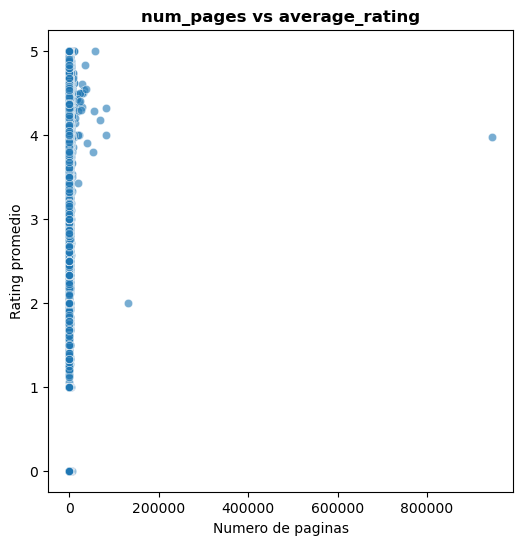

In [ ]:
plot_scatter_rating_por_num_pages(df_us_en)

Del grafico notamos que hay outliers en la cantidad de paginas, consideramos que habria que eliminar estos puntos.

Aparte, observamos que para una misma cantidad de hojas el rating varia muchismo (adopta casi todo los valores posibles), interpretamos que esta no sera una feature que por si sola determine significativamente el target.

Chequeamos el minimo y maximo de cantidad de hojas (porque no tendria sentido, por ejemplo, un libro con 0 hojas...)

In [ ]:
print(f"Max en num_pages: {df_us_en["num_pages"].max()}")
print(f"Min en num_pages: {df_us_en["num_pages"].min()}")

945077.0
0.0


En la seccion 3 eliminamos estos outliers y valores ilogicos. Mientras tanto, volvemos a graficar la cantidad de paginas, esta vez teniendo en cuenta unicamente los valores razonables.

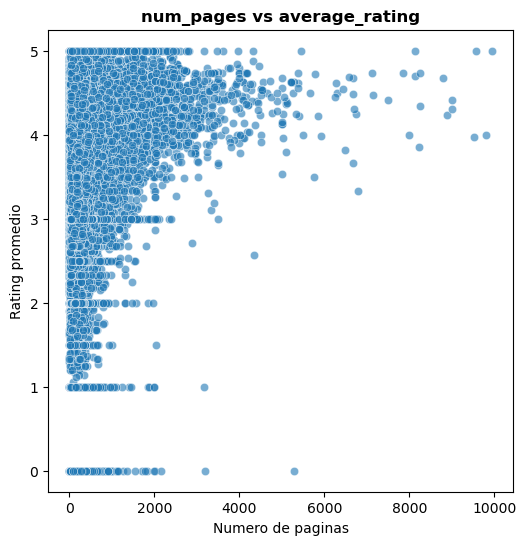

In [11]:
plot_scatter_rating_por_num_pages(df_us_en[(df_us_en["num_pages"] >= 1) & (df_us_en["num_pages"] <= 10000)])

Con esta nueva escala se puede apreciar mejor la distribucion de los libros, pero no encontramos una relacion clara entre la cantidad de paginas y el rating promedio. 

### Analizando "publication_year"

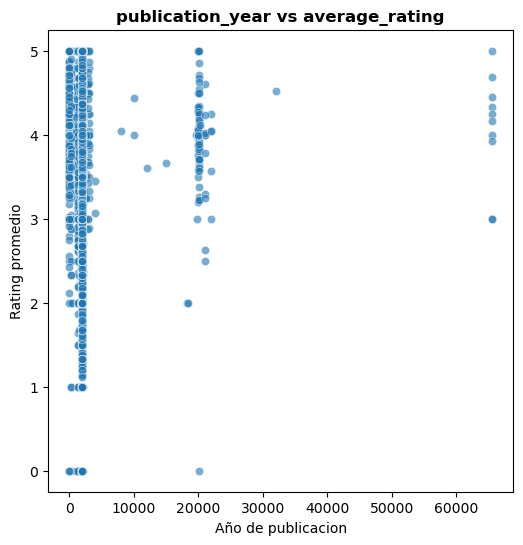

In [ ]:
plot_scatter_rating_por_publication_year(df_us_en)

Al igual que con "num_pages", a esta escala, pareceria que la feature no es muy relevante para el target. Y posee muchos valores mal cargados, no tiene sentido que el año de publicacion sea mas grande que 2026...

Veamos en un escala mas chica (rango de años mas razonable):

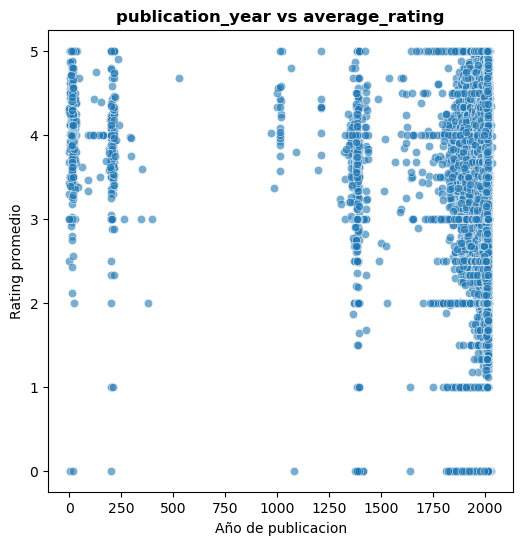

In [ ]:
df_filtrado_publi_year = df_us_en[df_us_en["publication_year"] <= 2040]
plot_scatter_rating_por_publication_year(df_filtrado_publi_year)

A simple vista no se puede identificar una fuerte realcion entre el target y esta variable, pero seguimos descubriendo posible outliers, los que estan cerca de 0. 

In [ ]:
df_us_en.to_pickle("checkpoint_fusion5.pkl")

## 2.5 Generando la feature "genero"

El dataset presenta la feature popular_shelves, que contiene las bibliotecas mas elegidas por los usuarios para guardar el libro. Utilizamos esta informacion para deducir los generos predominantes del libro. Por mas que esta feature haya salido de la interaccion de los usuarios, el genero es una caracteristica objetiva del libro, independientemente de la percepcion del usuario. Esta dada antes de la publicacion del libro, solo que este dataset no cuenta con ella. Es por esto que consideramos pertinente usarla. 

In [38]:
for i in range(5): #imprimo algunos ejemplos de las bibliotecas mas elegidas para guardar el libro
    print(f"Libro {i}")
    print(df_us_en["popular_shelves"].iloc[i])
    print()

Libro 0
[{'count': '3', 'name': 'to-read'}, {'count': '1', 'name': 'p'}, {'count': '1', 'name': 'collection'}, {'count': '1', 'name': 'w-c-fields'}, {'count': '1', 'name': 'biography'}]

Libro 1
[{'count': '2634', 'name': 'to-read'}, {'count': '160', 'name': 'fiction'}, {'count': '92', 'name': 'currently-reading'}, {'count': '25', 'name': 'contemporary-fiction'}, {'count': '22', 'name': 'owned'}, {'count': '19', 'name': 'book-club'}, {'count': '17', 'name': 'chick-lit'}, {'count': '16', 'name': 'friendship'}, {'count': '15', 'name': 'books-i-own'}, {'count': '12', 'name': 'novel'}, {'count': '12', 'name': 'general-fiction'}, {'count': '11', 'name': 'anita-diamant'}, {'count': '10', 'name': 'owned-books'}, {'count': '10', 'name': 'contemporary'}, {'count': '10', 'name': 'women'}, {'count': '8', 'name': 'adult'}, {'count': '7', 'name': 'default'}, {'count': '7', 'name': 'favorites'}, {'count': '7', 'name': 'didn-t-finish'}, {'count': '6', 'name': 'own-it'}, {'count': '6', 'name': 'librar

In [12]:
#imprimo las estanterias mas populares
chunks = pd.read_json("goodreads_us_english.json", lines=True, chunksize=100_000)
contador = Counter()
for chunk in tqdm(chunks):
    for shelves in chunk["popular_shelves"]:
        for shelf in shelves:
            contador[shelf["name"]] += int(shelf["count"])
contador.most_common(50)

20it [04:28, 13.44s/it]


[('to-read', 4930080153),
 ('currently-reading', 323505192),
 ('favorites', 168678540),
 ('classics', 146774656),
 ('fiction', 141499351),
 ('fantasy', 102357451),
 ('young-adult', 50212844),
 ('books-i-own', 46063532),
 ('owned', 44305203),
 ('romance', 35051523),
 ('historical-fiction', 29878626),
 ('classic', 29488169),
 ('mystery', 28156117),
 ('science-fiction', 24721369),
 ('ya', 22845326),
 ('non-fiction', 22126972),
 ('sci-fi', 19853644),
 ('series', 19845219),
 ('kindle', 18881784),
 ('favourites', 17031116),
 ('literature', 16159710),
 ('owned-books', 15454073),
 ('horror', 14479657),
 ('book-club', 13415393),
 ('default', 13375681),
 ('library', 12842717),
 ('contemporary', 12058307),
 ('audiobook', 11931285),
 ('paranormal', 11678342),
 ('novels', 11649309),
 ('to-buy', 11467827),
 ('historical', 11366849),
 ('childrens', 11091620),
 ('adventure', 10574054),
 ('adult', 10274829),
 ('ebook', 9944791),
 ('history', 9868281),
 ('audiobooks', 9692662),
 ('nonfiction', 9510917),

Varias de estas estanterias no son generos (ej: to-read). En base a estos ejemplos (y muchos libros mas), creamos una funcion que detecta diferentes maneras de llamar a un mismo genero. Por ejemplo, "young-adult" y "ya" corresponden al mismo genero. Aparte, si un libro tiene como genero "historical-fiction" se podria decir que tiene como generos "historical" y "fiction". Filtro estos diccionarios para extraer una lista de generos para cada libro.

In [13]:
df_us_en["genres"] = df_us_en["popular_shelves"].apply(extraer_generos_libro)

sin_genero = (df_us_en["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero/len(df_us_en):.2f}%")

Porcentaje de libros sin genero: 12.35%


Una vez aplicada esta funcion, noto que el 12% de los libros no tienen genero. Viendo algunos libros, noto que de base el diccionario no tenia generos, no es que la funcion no esta detectando correctamente variantes de generos. 

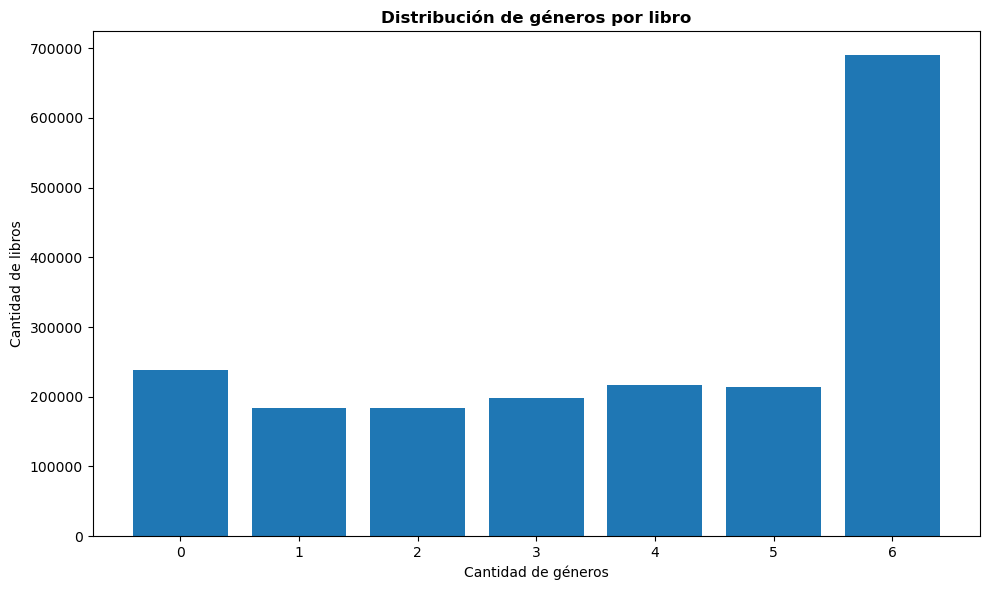

In [41]:
plot_cantidad_generos_por_libro(df_us_en)

En un primer momento, este grafico mostraba que habia libros con 18 generos. Varios de estos eran falsos positivos o ruido. Para evitar esto, elijo un maximo de 6 generos por libro.
Estas distribuciones resultan mucho mas razonables

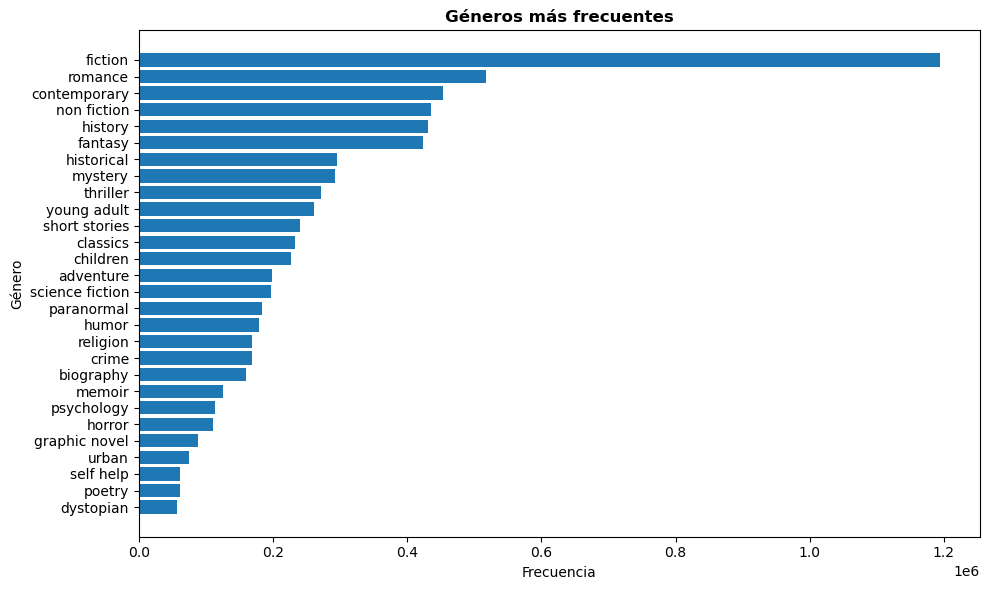

In [42]:
contador_generos = (df_us_en["genres"].explode().value_counts()) #.explode() separa los elementos de la lista
plot_generos_mas_frecuentes(contador_generos)

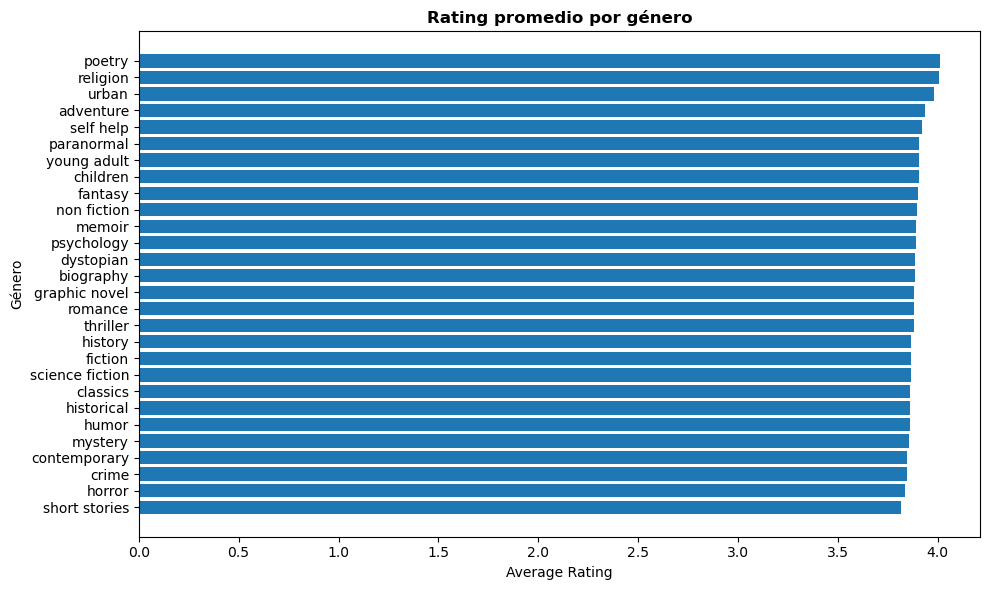

In [ ]:
plot_rating_por_genero(df_us_en)

Hay una leve diferencia entre el rating de los generos, pero esta permanece entre 3.7 y 4. No consideramos que haya una influencia significativa del genero (por si solo) en el rating.

<Figure size 1200x600 with 0 Axes>

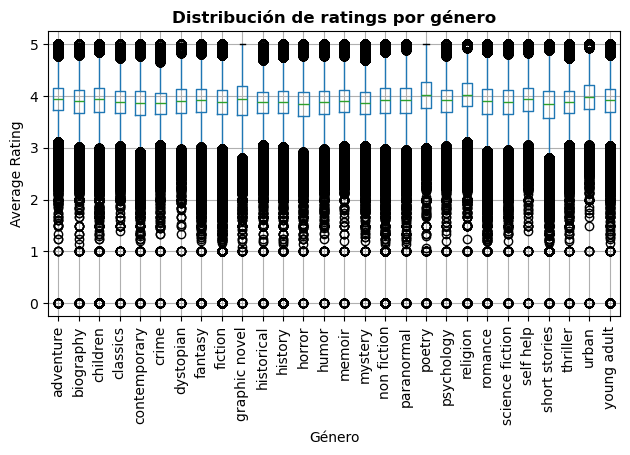

In [44]:
plot_boxplot_rating_por_genero(df_us_en)

In [17]:
df_us_en.to_pickle("checkpoint_fusion6.pkl")

## 2.6 Analizando la feature "author"

In [14]:
#Creamos una nueva feature n_authors, que contiene la cantidad de autores de un libro
df_us_en.loc[:, "n_authors"] = df_us_en["authors"].apply(len)

print("Distribución de cantidad de autores por libro:")
print(f"\n% con 1 solo autor: {(df_us_en['n_authors'] == 1).mean():.1%}")
print(f"% con mas de 2 autores: {(df_us_en['n_authors'] >= 2).mean():.1%}")
print(f"% con 0 autores: {(df_us_en['n_authors'] == 0).mean():.1%}")

#DECISION: elimino los pocos libros que no tienen ningun autor (la lista de diccionarios esta vacia)
df_us_en = df_us_en[df_us_en["authors"].apply(len) > 0]

Distribución de cantidad de autores por libro:

% con 1 solo autor: 80.0%
% con mas de 2 autores: 20.0%
% con 0 autores: 0.0%


In [46]:
#Todos los roles que aparecen, con su frecuencia
roles = (df_us_en["authors"].explode().apply(lambda x: x["role"]).value_counts())
total_roles = roles.sum()
print("Frecuencia de cada rol:")

for role, count in roles[:20].items():
    if role != "":
        label = role 
    else: 
        label = ""
    print(f"  {label}: {count} ({count/total_roles:.1%})")

Frecuencia de cada rol:
  : 2182358 (82.6%)
  Illustrator: 92318 (3.5%)
  Contributor: 81001 (3.1%)
  Editor: 70273 (2.7%)
  Narrator: 38452 (1.5%)
  Translator: 31052 (1.2%)
  Illustrations: 26517 (1.0%)
  Introduction: 11932 (0.5%)
  Foreword: 10637 (0.4%)
  Artist: 6257 (0.2%)
  Translation: 5968 (0.2%)
  Reading: 5952 (0.2%)
  Writer: 5167 (0.2%)
  Creator: 3872 (0.1%)
  Photographer: 3645 (0.1%)
  Text: 3376 (0.1%)
  contributor: 3281 (0.1%)
  Foreword by: 2855 (0.1%)
  editor: 2360 (0.1%)
  narrator: 2252 (0.1%)


Muchos libros tienen mas de un autor, pero al analizar a detalle, nos damos cuenta de que lo mas probable es que no sean dos escritores a la vez, sino un autor y un editor, o un traductor. Decidimos quedarnos unicamente con el autor principal (usualmente con rol " " = vacio). 

In [47]:
df_us_en["primer_es_vacio"] = df_us_en["authors"].apply(primer_tiene_role_vacio)

print("¿El primer autor de la lista tiene role vacío?")
print(df_us_en["primer_es_vacio"].value_counts(normalize=True))

¿El primer autor de la lista tiene role vacío?
primer_es_vacio
True     0.967719
False    0.032281
Name: proportion, dtype: float64


En base a estos analisis, decidio extraer el autor principal de la siguiente manera:
Noto que si el valor de "role" esta vacio (que es la mayoria de los casos), es el autor (en sentido de escritor). En caso de que haya varios, devuelvo el primero, el principal.

In [19]:
df_us_en["author_id_principal"] = df_us_en["authors"].apply(extraer_autor_principal)

In [50]:
top_autores = df_us_en["author_id_principal"].value_counts().head(10)
print(top_autores)

author_id_principal
123715     2713
5158478    2420
3780       2164
3389       2049
947        1856
625        1617
239579     1494
2448       1397
1265       1263
1654       1118
Name: count, dtype: int64


In [51]:
for autor_id in top_autores.index:
    print(f"\nAutor {autor_id}")
    print(df_us_en[df_us_en["author_id_principal"] == autor_id]["title"].head(20).to_list())


Autor 123715
['A Murder is Announced', '4:50 From Paddington', 'The Mysterious Affair at Styles (Hercule Poirot Book 1)', "Mrs. McGinty's Dead", 'Third Girl (Hercule Poirot, #35)', 'Cat Among the Pigeons', 'Un Gato en el Palomar', 'Death Comes as the End', 'Death In The Clouds', 'Murder on the Links', "Mrs. McGinty's Dead: A BBC Radio 4 Full-Cast Dramatisation", 'The Chocolate Box', 'Poirot Investigates', 'Cards on the Table (Hercule Poirot #15)', "Dead Man's Folly (Hercule Poirot, #31)", "Why Didn't They Ask Evans?", 'Det Forstenede Ansigt', 'Crooked House', 'Meurtre au champagne', 'Partners in Crime (Tommy and Tuppence #2)']

Autor 5158478
['Stress Less and Enjoy Each Day: 10 Principles to Help You Reduce Tension and Enjoy More Peace', 'Koine Greek New Testament', 'Lawmen & Outlaws', 'The Táin', 'The Passion of Mademoiselle S.: Letters to a Lover', 'Vikram and the Vampire: Classic Hindu Tales of Adventure Magic and Romance', "Webster's Compact Rhyming Dictionary", 'The Complete I Ch

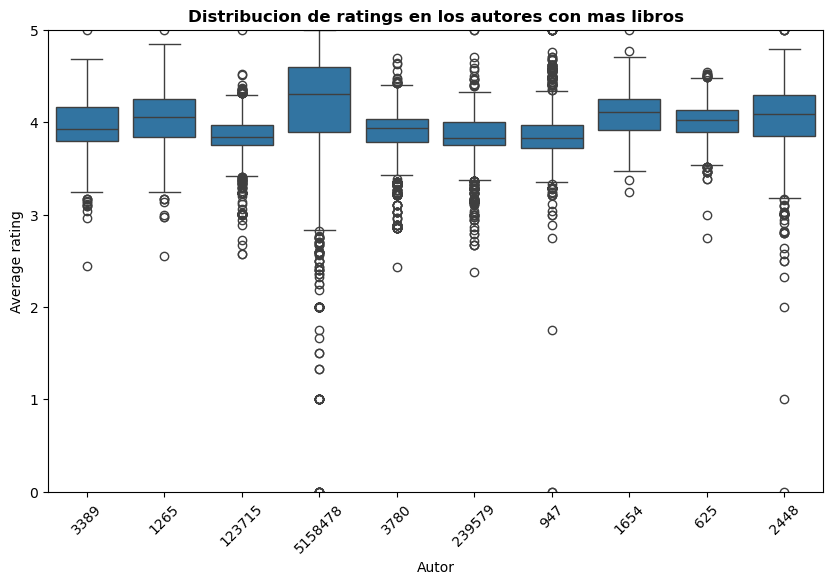

In [53]:
autores_top = top_autores.index
df_top = df_us_en[df_us_en["author_id_principal"].isin(autores_top)]
plot_boxplot_rating_por_autor_frecuent(df_top, "Distribucion de ratings en los autores con mas libros")

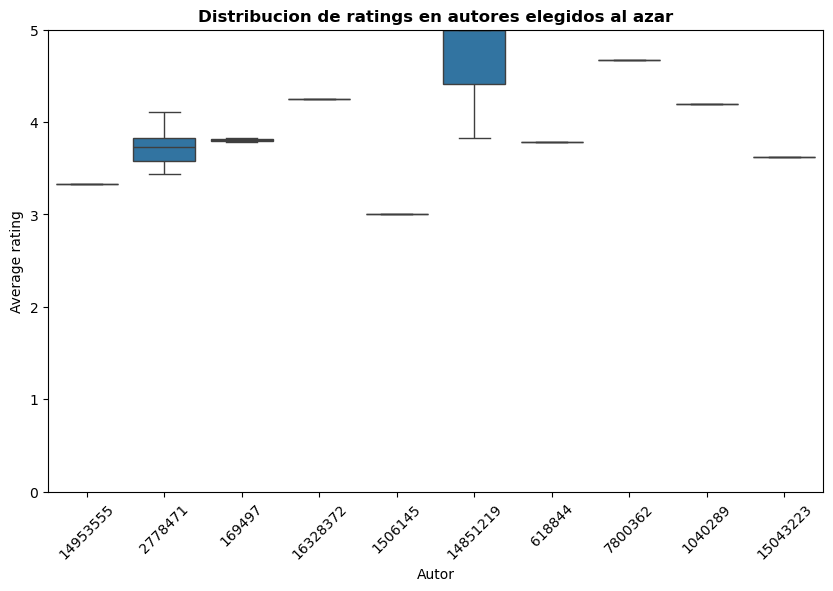

In [54]:
autores_random = df_us_en["author_id_principal"].drop_duplicates().sample(10, random_state = 42)
df_random = df_us_en[df_us_en["author_id_principal"].isin(autores_random)]
plot_boxplot_rating_por_autor_frecuent(df_random, "Distribucion de ratings en autores elegidos al azar")

Los autores con muchos libros tienen un rating promedio de 4. Sin embargo, cuando tomamos autores que no publicaron tantos libros observamos resultados mas dispersos.

In [20]:
df_us_en.to_pickle("checkpoint_fusion7.pkl")

## 2.7 Problema: libros repetidos

In [ ]:
print("Filas totales:", len(df_us_en))
print("Duplicados por título:")
print(df_us_en["title"].duplicated().sum())

Filas totales: 1925859
Duplicados por título:
529280


In [57]:
duplicados = df_us_en[df_us_en["title"].duplicated(keep = False)]
cantidad_por_titulo = duplicados.groupby("title").size().sort_values(ascending = False)
print(cantidad_por_titulo.head(20))

title
Selected Poems                      299
Pride and Prejudice                 298
Jane Eyre                           258
Wuthering Heights                   256
Dracula                             227
Frankenstein                        206
A Christmas Carol                   190
The Great Gatsby                    177
The Picture of Dorian Gray          174
Emma                                168
Great Expectations                  162
The Secret Garden                   161
Sense and Sensibility               153
Treasure Island                     148
Alice's Adventures in Wonderland    141
Little Women                        134
Persuasion                          133
The Scarlet Letter                  130
Anna Karenina                       130
A Tale of Two Cities                129
dtype: int64


Los duplicados pueden indicar diferentes ediciones de un mismo libro. Esto tiene sentido ya que los libros mencionados son muy conocidos, tiene sentido que hayan sido publicados multiples veces.

Veamos como ejemplo un caso especifico de los que aparecen ahi, para analizar el problema en mas detalle:

In [63]:
df_us_en[df_us_en["title"] == "Pride and Prejudice"][["title", "authors", "publisher", "publication_year", "num_pages", "format_group", "average_rating", "ratings_count"]].head(20)

,title,authors,publisher,publication_year,num_pages,format_group,average_rating,ratings_count
6607,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",YBM Si-sa,2006.0,239.0,PAPERBACK,4.25,710
12730,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Arcturus,2009.0,352.0,PAPERBACK,4.25,265
27187,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Sterling Publishing,2012.0,325.0,HARDCOVER,4.25,10
59852,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Public Domain,2010.0,472.0,EBOOK,4.25,3
94128,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Signet Classics,1961.0,NaN,PAPERBACK,4.25,30
107186,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Penguin,NaN,346.0,UNKNOWN,4.25,147
108830,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Recorded Books,2006.0,692.0,AUDIO,4.25,7
110494,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",Signet Classic,1996.0,324.0,UNKNOWN,4.25,360
145723,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}]",Sourcebooks,2010.0,258.0,EBOOK,4.25,41
146272,Pride and Prejudice,"[{'author_id': '1265', 'role': ''}, {'author_i...",BBC Books,2014.0,1.0,AUDIO,4.25,5


Ahora, veamos cuantas muestras comparten el mismo titulo Y el mismo autor (porque si solo coinciden en titulo, pero su autor es diferente, entonces son obras distintas):

In [64]:
duplicados = (df_us_en.groupby(["title", "author_id_principal"]).size().sort_values(ascending=False))
duplicados.head(20)

title                             author_id_principal
Pride and Prejudice               1265                   293
Jane Eyre                         1036615                253
Wuthering Heights                 4191                   248
Dracula                           6988                   214
Frankenstein                      11139                  198
A Christmas Carol                 239579                 181
The Great Gatsby                  3190                   172
The Picture of Dorian Gray        3565                   171
Great Expectations                239579                 157
The Secret Garden                 2041                   154
Emma                              1265                   153
Sense and Sensibility             1265                   148
Treasure Island                   854076                 141
Alice's Adventures in Wonderland  8164                   139
Persuasion                        1265                   132
Little Women                   

Fusionamos los libros repetidos:

In [ ]:
#1.Tenemos que tener seguro el autor para cada muestra (seccion 2.6)
#2.Escribimos el titulo en minusculas para que sean comparables entre muestras (por si es el mismo nombre, pero con algo diferente):
df_us_en["title_key"] = (df_us_en["title"].str.lower().str.strip())
df_us_en["ratings_count"] = pd.to_numeric(df_us_en["ratings_count"], errors="coerce")
df_us_en = (df_us_en.groupby(["title_key", "author_id_principal"], as_index = False).apply(fusionar_libros).reset_index(drop = True))

/var/folders/vz/dvp73rjn6bb_xqcp58j9_h900000gn/T/ipykernel_1343/1098386180.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_us_en = (df_us_en.groupby(["title_key", "author_id_principal"], as_index = False).apply(fusionar_libros).reset_index(drop = True))


In [22]:
df_us_en.to_pickle("checkpoint_fusion8.pkl")

## 2.8 Analizando "publisher"

In [ ]:
top_publishers = df_us_en["publisher"].value_counts().head(10)
print(top_publishers)

publisher
                                               391631
Createspace Independent Publishing Platform     15868
Smashwords Edition                               9856
Createspace                                      7974
Harlequin                                        7951
Oxford University Press, USA                     5717
HarperCollins                                    4505
Marvel                                           4321
Amazon Digital Services                          4185
Penguin Books                                    4056
Name: count, dtype: int64


In [ ]:
publishers_unique = df_us_en["publisher"].unique()

In [ ]:
print(len(publishers_unique))

118749


In [2]:
df_us_en = pd.read_pickle("checkpoint_fusion8.pkl")

## 2.9 Analizando language code
Antes habiamos notado que muchas de estas muestras presentaban strings vacios, nos encargamos de esto. 

In [3]:
mask_lang = df_us_en["language_code"].fillna("").str.strip().eq("")
muestras_vacias_lang = df_us_en[mask_lang]
print(muestras_vacias_lang.shape)
display(muestras_vacias_lang.head(20))

(853845, 15)


,title_key,author_id_principal,title,authors,publisher,publication_year,num_pages,language_code,average_rating,ratings_count,genres,format_group,description,title_text,is_series
0,,1157123,,"[{'author_id': '1157123', 'role': ''}]",Book Thug,2010.0,63.0,,4.79,14,[poetry],[PAPERBACK],"Poetry. ""In the magical dictionary of (MADE), ...",,False
3,,2713,,"[{'author_id': '2713', 'role': ''}]",Yearling,1985.0,160.0,,3.63,8,"[children, contemporary, fantasy, fiction, psy...",[PAPERBACK],Ben has always been content to be brilliant at...,,False
4,,39194,,"[{'author_id': '39194', 'role': ''}]",,NaN,NaN,,3.64,2,"[classics, contemporary, fantasy, fiction, non...",[UNKNOWN],Con una Barcelona de claroscuros y contrastes ...,,False
5,,76704,,"[{'author_id': '76704', 'role': ''}]",Rain Taxi,2003.0,23.0,,4.40,5,[poetry],[PAPERBACK],,,False
6,,8622352,,"[{'author_id': '8622352', 'role': ''}]",AO3,2014.0,NaN,,3.50,2,[young adult],[OTHER],"Derek is a socially awkward, struggling writer...",,False
7,!búscalo! (look it up!): a quick reference gui...,663466,!Búscalo! (Look It Up!): A Quick Reference Gui...,"[{'author_id': '663466', 'role': ''}]",Wiley,1998.0,224.0,,3.78,9,[non fiction],[PAPERBACK],A novel approach--very useful for quick refere...,!Búscalo! (Look It Up!): A Quick Reference Gui...,False
8,!exacto!: a practical guide to spanish grammar,729800,!Exacto!: A Practical Guide to Spanish Grammar,"[{'author_id': '729800', 'role': ''}]",McGraw-Hill,NaN,256.0,,4.00,3,[non fiction],[PAPERBACK],"The innovative, user-friendly ""Exacto ""is trul...",!Exacto!: A Practical Guide to Spanish Grammar,False
9,!feliz navidad: celebrating a mexican christmas,9508434,!Feliz Navidad: Celebrating a Mexican Christmas,"[{'author_id': '9508434', 'role': 'Contributor'}]",World Book,2015.0,NaN,,5.00,1,"[children, history, religion]",[HARDCOVER],"""A study of the celebrations, customs, and pra...",!Feliz Navidad: Celebrating a Mexican Christmas,False
10,!fish! la eficacia de un equipo radica en su c...,32803,!Fish! La Eficacia de un Equipo Radica en Su C...,"[{'author_id': '32803', 'role': ''}, {'author_...",Ediciones Urano,2004.0,128.0,,3.93,20,"[fiction, non fiction, psychology, self help]",[PAPERBACK],Fish and its ideas show us how to renew the in...,!Fish! La Eficacia de un Equipo Radica en Su C...,False
11,!بوب..موب..عمي,7939238,!بوب..موب..عمي,"[{'author_id': '7939238', 'role': ''}]",dr mdrk,2014.0,381.0,,3.22,617,"[fiction, romance]",[UNKNOWN],,!بوب..موب..عمي,False


Al imprimir algunos libros del dataset para analizar el idioma, nos damos cuenta que algunos estan en ingles, mientras que otros no. Para evitar tener que eliminar automaticamente todas estas muestras, usamos una libreria que detecta los diferentes idiomas. Nos quedamos con los que esta libreria detecta como ingles. 

In [ ]:
#para que los resultados sean reproducibles
DetectorFactory.seed = 42
#tomamos una muestra
sample = (df_us_en[df_us_en["language_code"] == ""].sample(1000, random_state = 42).copy())
sample["detected_language"] = sample.apply(detectar_language_code, axis=1)
print(sample["detected_language"].value_counts(normalize=True).mul(100).round(2))

detected_language
en    88.4
es     1.5
de     1.2
fr     0.9
id     0.8
nl     0.8
cy     0.8
af     0.7
ar     0.7
it     0.6
da     0.4
no     0.4
sv     0.3
tr     0.3
so     0.3
lt     0.3
tl     0.3
et     0.2
hr     0.2
hu     0.2
pt     0.1
fi     0.1
ko     0.1
ca     0.1
vi     0.1
ro     0.1
sk     0.1
Name: proportion, dtype: float64


Casi el 90% de los libros sin idioma registrado estan en ingles, nos quedamos con estas muestras.

In [ ]:
df_us_en["language_code"] = df_us_en["language_code"].fillna("").astype(str).str.strip()
df_us_en.loc[df_us_en["language_code"] == "", "detected_language"] = (df_us_en.loc[df_us_en["language_code"] == ""].apply(detectar_language_code, axis=1))
print("Filas antes:", len(df_us_en))
#Conservamos las muestras con language_code original y != "", y filas con ese valor vacío, pero detectado como ingles:
df_us_en = df_us_en[(~(df_us_en["language_code"] == "")) | ((df_us_en["language_code"] == "") & (df_us_en["detected_language"] == "en"))]

#Completamos con "eng" los que fueron detectados como ingles:
df_us_en.loc[(df_us_en["language_code"] == "") &(df_us_en["detected_language"] == "en"), "language_code"] = "eng"

#Eliminamos la columna auxiliar creada:
df_us_en.drop(columns = ["detected_language"], inplace = True )

print("Filas después:", len(df_us_en))
print(df_us_en["language_code"].value_counts())

Filas antes: 1478917
Filas después: 1390363
language_code
eng      1282630
en-US      61469
en-GB      41065
en-CA       5055
en            99
enm           20
sco           13
ang            9
gem            3
Name: count, dtype: int64


## 2.10 Correlacion entre features

Ahora ya podemos aplicar las transformaciones necesarias para el analisis: <br>
Un libro puede tener varios formatos luego de la fusion, por lo que en vez de aplicar one hot encoding, aplicamos multi binarizer, que aplica la misma logica pero permite Trues (o 1s) en mas de una opcion. <br>
Aplicamos multi binarizer a genero por la misma logica. Y a la feature language le aplicamos one hot encoding. <br>
Necesito estas transformaciones para poder calcular la correlacion con el target. 

In [6]:
#Realizo las transformaciones necesarias:
df_us_en = multi_binarizer_format(df_us_en) #multi binarizer de format
df_us_en = multi_binarizer_genre(df_us_en) #multi binarizer de genero
df_us_en = one_hot_language(df_us_en) #one hot de language_code

In [4]:
df_us_en.to_pickle("checkpoint_fusion9.pkl")

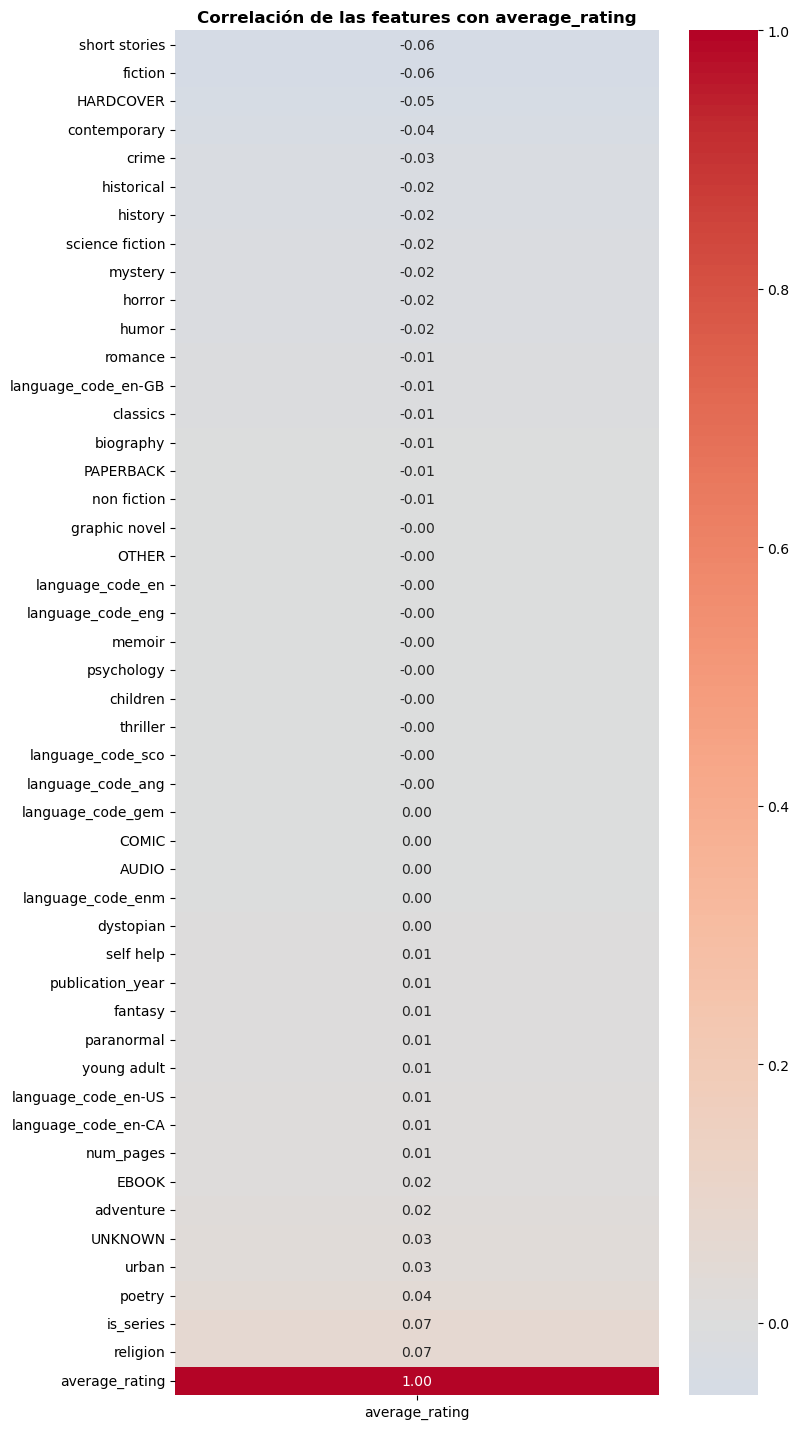

In [8]:
generos = ["fiction", "non fiction", "fantasy", "science fiction", "mystery", "thriller", "romance", "horror", "historical", "young adult", "children", "adventure", "contemporary", "dystopian", "paranormal", "urban", "crime", "biography", "memoir", "self help", "history", "psychology", "poetry", "classics", "graphic novel", "short stories", "humor", "religion"]
features = ["is_series", "publication_year", "num_pages", "AUDIO", "COMIC", "EBOOK", "HARDCOVER", "OTHER", "PAPERBACK", "UNKNOWN", "language_code_en", "language_code_eng", "language_code_en-US", "language_code_en-GB", "language_code_en-CA", "language_code_enm", "language_code_ang", "language_code_sco", "language_code_gem"] + generos

#correlacion con el target
corr_rating = (df_us_en[features + ["average_rating"]].corr(numeric_only=True)["average_rating"].sort_values())
plot_correlacion_features(corr_rating)

Por si solas, estas features no aportan mucha informacion al modelo. Sin embargo, podemos intentar con algunas combinaciones:
- young adult * romance
- young adult * fantasy
- mystery * thriller
- len(generos) <br>


Aparte, mas adelante vamos a generar nuevas features usando embeddins, o un procesado mas minucioso de los autores y publishers. 

In [7]:
df_us_en.to_pickle("checkpoint_fusion11.pkl")

# 3. Continuamos el preprocesamiento (se empezo un poco antes del EDA):

In [12]:
missing_summary = pd.DataFrame({
    "missing_count": df_us_en.isna().sum(),
    "missing_pct": df_us_en.isna().mean() * 100,
    "empty_string_count": (df_us_en == "").sum()
})
print(missing_summary)

                     missing_count  missing_pct  empty_string_count
title_key                        0     0.000000                   5
author_id_principal              0     0.000000                   0
title                            0     0.000000                   5
authors                          0     0.000000                   0
publisher                        0     0.000000              391631
publication_year            337706    24.289053                   0
num_pages                   473761    34.074627                   0
language_code                    0     0.000000                   0
average_rating                   0     0.000000                   0
ratings_count                    0     0.000000                   0
genres                           0     0.000000                   0
format_group                     0     0.000000                   0
description                      0     0.000000              242123
title_text                       0     0.000000 

Analizo los valores faltantes de la feature "description": 

Como vamos a hacerles embeddings, puedo hacerle el embedding a un string vacio. Entonces, lo dejamos asi.

In [13]:
(df_us_en["description"].fillna("").str.split().str.len().quantile([0.25, 0.5, 0.75, 0.9, 0.95]))

0.25     40.0
0.50    111.0
0.75    175.0
0.90    242.0
0.95    295.0
Name: description, dtype: float64

En base a la longitud de los valores y al hecho de que esta tecnica es capaz de capturar el signficado del texto (coloca en el espacio vectorial a palabras con significados similares juntas), decidimos suar embeddings en vez de TF-IDF

Analizando los valores flatantes de "publisher":

In [14]:
df_us_en["publisher"].nunique()

118749

In [15]:
df_us_en["publisher"] = (df_us_en["publisher"].replace("", "UNKNOWN_PUBLISHER"))

Las features "publication_year" y "num_pages" presetan valores NaN y algunos registros con valores extremos (ilogicos).  Como creemos que no hay una estrategia de imputacion que permita estimar esos valores de forma confiable y acorde a cada muestra en particular (la media o mediana no tendrian mucho sentido en estos casos), decidimos quedarnos solamente con las muestras que poseen años de publicacion  comprendidos entre 1440 (comienzo de la impresion) y 2026, y cantidad de paginas entre 1 y 10000. Este filtrado elimina simultaneamente aquellos datos que poseen algun valor faltante para alguna de estas dos caracterisitcas (este porcentaje de muestras es insignificante en comparacion a la cantidad total de datos que se posee).


In [ ]:
mask = df_us_en['publication_year'].between(1440, 2026) & df_us_en["num_pages"].between(1, 10000) #1440 es el año en que se invento la impresion
df_us_en = df_us_en[mask]


Ahora, tenemos que eliminar las observaciones poco confiables. Es decir, aquellas que poseen rating_count bajo (ya que indica que poseen un average_rating volatil):

In [17]:
bins_s4 = [0,1,2,5,10,20,50,100,500,np.inf]

df_us_en.groupby(pd.cut(df_us_en["ratings_count"], bins_s4))["average_rating"].agg(["count","mean","std"])

/var/folders/vz/dvp73rjn6bb_xqcp58j9_h900000gn/T/ipykernel_14539/1433624720.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_us_en.groupby(pd.cut(df_us_en["ratings_count"], bins_s4))["average_rating"].agg(["count","mean","std"])


,count,mean,std
ratings_count,,,
"(0.0, 1.0]",45606,3.901770,0.969463
"(1.0, 2.0]",36906,3.945884,0.776893
"(2.0, 5.0]",81285,3.947335,0.635582
"(5.0, 10.0]",89729,3.921281,0.528657
"(10.0, 20.0]",108440,3.886219,0.459560
"(20.0, 50.0]",151502,3.852801,0.402726
"(50.0, 100.0]",102565,3.839862,0.364548
"(100.0, 500.0]",157993,3.859600,0.328279
"(500.0, inf]",104069,3.927824,0.282121


Como sospechabamos, a medida que rating_count aumenta, disminuye el desvio estandar (la dispersion) del rating.

La caida mas fuerte ocurre en el rango de rating_count comenzando en (0.0, 1.0] hasta el de (5.0, 10.0]. Luego de ese rango, sigue bajando el std, pero mucho mas gradualmente. 

In [18]:
len(df_us_en)

882068

In [19]:
len(df_us_en[df_us_en["ratings_count"] >= 10])

639491

Si hicieramos el corte en 10, perderiamos un 27.5% de mustras, aproximadamente (((882068 - 639491) / 639491) * 100).

In [20]:
len(df_us_en[df_us_en["ratings_count"] >= 20])

524505

En cambio, si hicieramos el corte en 20, perderiamos un 40.5% de mustras, aproximadamente (((882068 - 524505) / 882068) * 100).

Y si vemos la tabla de progreso de estabilidad, observamos que (10.0, 20.0] tiene un std ~ 0,46 y (20.0, 50.0] tiene un std ~ 0,4. Es decir, que hay un 0,06 de mejora, lo cual no nos parece tan significante como para perder 114986 muestras adicionales (639491 - 524505).

In [22]:
df_us_en = df_us_en[df_us_en["ratings_count"] >= 10]

In [27]:
df_us_en.to_pickle("checkpoint_fusion12.pkl")

Aplicamos el filtro para la feature "genero":

In [23]:
sin_genero_s4 = (df_us_en["genres"].str.len() == 0).sum()
print(f"Porcentaje de libros sin genero: {100*sin_genero_s4/len(df_us_en):.2f}%")

Porcentaje de libros sin genero: 2.31%


In [ ]:
df_us_en.to_pickle("checkpoint_fusion13.pkl")

Como el porcentaje de muestras que poseen su feture genero vacia es muy bajo, podemos dejar el valor tal cual como esta ([]) (en vez de generar otra categoria artificial llamada, por ejemplo, "unknown") y usar nuestra MultiLabelBinarizer, la cual simplemente va a generar una lista de ceros.

Tambien queremos generar una nueva feature llamada cantidad_generos, la cual indicara en cuantos generos se clasifico al libro (para ver si tiene alguna relaicon con el rating o no):

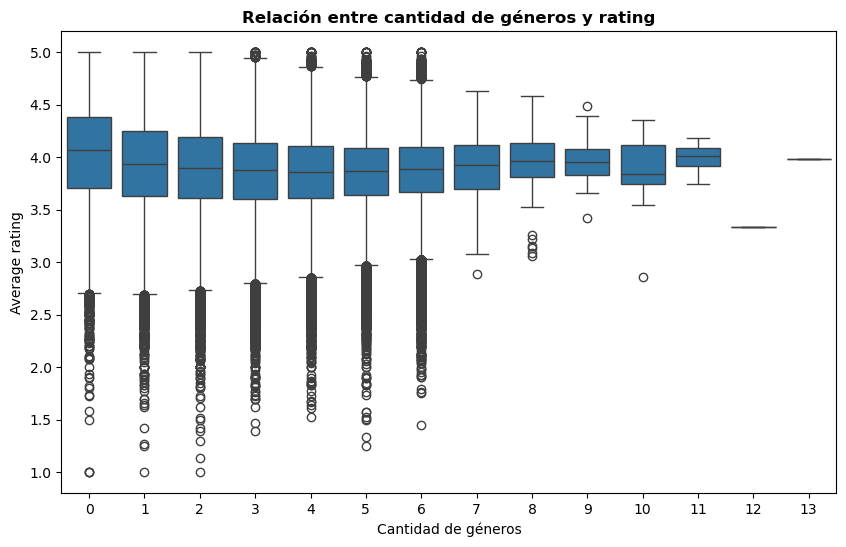

In [24]:
df_us_en["cantidad_generos"] = df_us_en["genres"].apply(len)
plot_boxplot_rating_por_cant_generos(df_us_en)

Mirando el boxplot, no parece haber una relacion fuerte entre la cantidad de generos asignados a una muestra y su average_rating. Excepto por el caso en el que las muestras poseen la lista de generos vacias, el resto de las opciones parecen tener medianas muy parecidas. 

En conclusion, en base a este grafico, creemos que la cantidad de generos probablemnte tenga una correlacion muy baja con el rating, pero tal vez los generos especificos si aporten mas al target. 

# 4. Splitting:

Analisis para ver si es necesario hacer split por autores:

In [ ]:
autor_counts = df_us_en.groupby("author_id_principal")["estrellas"].count()
print(f"Autores totales: {autor_counts.shape[0]}") 
print(f"Autores con 1 solo libro: {(autor_counts == 1).sum()} " f"({(autor_counts == 1).mean():.1%})") 
print(f"Autores con 2+ libros: {(autor_counts > 1).sum()} " f"({(autor_counts > 1).mean():.1%})") 
print(f"Libros que pertenecen a un autor con 2+ libros: {df_us_en['author_id_principal'].map(autor_counts).gt(1).mean():.1%}")

Autores totales: 219046
Autores con 1 solo libro: 131840 (60.2%)
Autores con 2+ libros: 87206 (39.8%)
Libros que pertenecen a un autor con 2+ libros: 79.4%


In [39]:
df_us_en.to_pickle("checkpoint_fusion14.pkl")

In [29]:
df_train, df_val, df_test = split_estratificado_autor(df_us_en, test_size = 0.15, val_size = 0.15)

print(f"Train: {len(df_train)} ({len(df_train)/len(df_us_en):.1%})")
print(f"Val: {len(df_val)} ({len(df_val)/len(df_us_en):.1%})")
print(f"Test: {len(df_test)} ({len(df_test)/len(df_us_en):.1%})")

#Verificacion: distribución de estrellas en cada split
for nombre, d in [("train", df_train), ("val", df_val), ("test", df_test)]:
    print(f"\n{nombre}:")
    print(d["estrellas"].value_counts(normalize = True).sort_index())

Train: 462879 (72.4%)
Val: 81959 (12.8%)
Test: 94653 (14.8%)

train:
estrellas
1    0.000028
2    0.001925
3    0.144962
4    0.817406
5    0.035679
Name: proportion, dtype: float64

val:
estrellas
1    0.000012
2    0.001842
3    0.149026
4    0.814188
5    0.034932
Name: proportion, dtype: float64

test:
estrellas
1    0.000032
2    0.001870
3    0.149388
4    0.813477
5    0.035234
Name: proportion, dtype: float64


In [41]:
df_train.to_pickle("checkpoint_train.pkl")

In [42]:
df_val.to_pickle("checkpoint_val.pkl")

In [43]:
df_test.to_pickle("checkpoint_test.pkl")

In [30]:
import json
output_path_train1 = "set_train_1.json"
chunk_size = 10000
with open(output_path_train1, "w", encoding="utf-8") as f:
    for start in range(0, len(df_train), chunk_size):
        chunk = df_train.iloc[start:start + chunk_size]
        records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
        for record in records:
            json.dump(record, f, ensure_ascii=False)
            f.write("\n")
print("Guardado en", output_path_train1)

Guardado en set_train_1.json


In [31]:
import json
output_path_val1 = "set_val_1.json"
chunk_size = 10000
with open(output_path_val1, "w", encoding="utf-8") as f:
    for start in range(0, len(df_val), chunk_size):
        chunk = df_val.iloc[start:start + chunk_size]
        records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
        for record in records:
            json.dump(record, f, ensure_ascii=False)
            f.write("\n")
print("Guardado en", output_path_val1)

Guardado en set_val_1.json


In [32]:
import json
output_path_test1 = "set_test_1.json"
chunk_size = 10000
with open(output_path_test1, "w", encoding="utf-8") as f:
    for start in range(0, len(df_test), chunk_size):
        chunk = df_test.iloc[start:start + chunk_size]
        records = chunk.where(pd.notna(chunk), None).to_dict(orient="records")
        for record in records:
            json.dump(record, f, ensure_ascii=False)
            f.write("\n")
print("Guardado en", output_path_test1)

Guardado en set_test_1.json


# 5. Analisis finales

In [33]:
#LEO TEST
chunks_test = pd.read_json("set_test_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_test:
    chunk_list.append(chunk)
df_test = pd.concat(chunk_list, ignore_index=True)

#LEO VAL
chunks_val = pd.read_json("set_val_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_val:
    chunk_list.append(chunk)
df_val = pd.concat(chunk_list, ignore_index=True)

#LEO TRAIN
chunks_train = pd.read_json("set_train_1.json", lines=True, chunksize=100_000)
chunk_list = []
for chunk in chunks_train:
    chunk_list.append(chunk)
df_train = pd.concat(chunk_list, ignore_index=True)

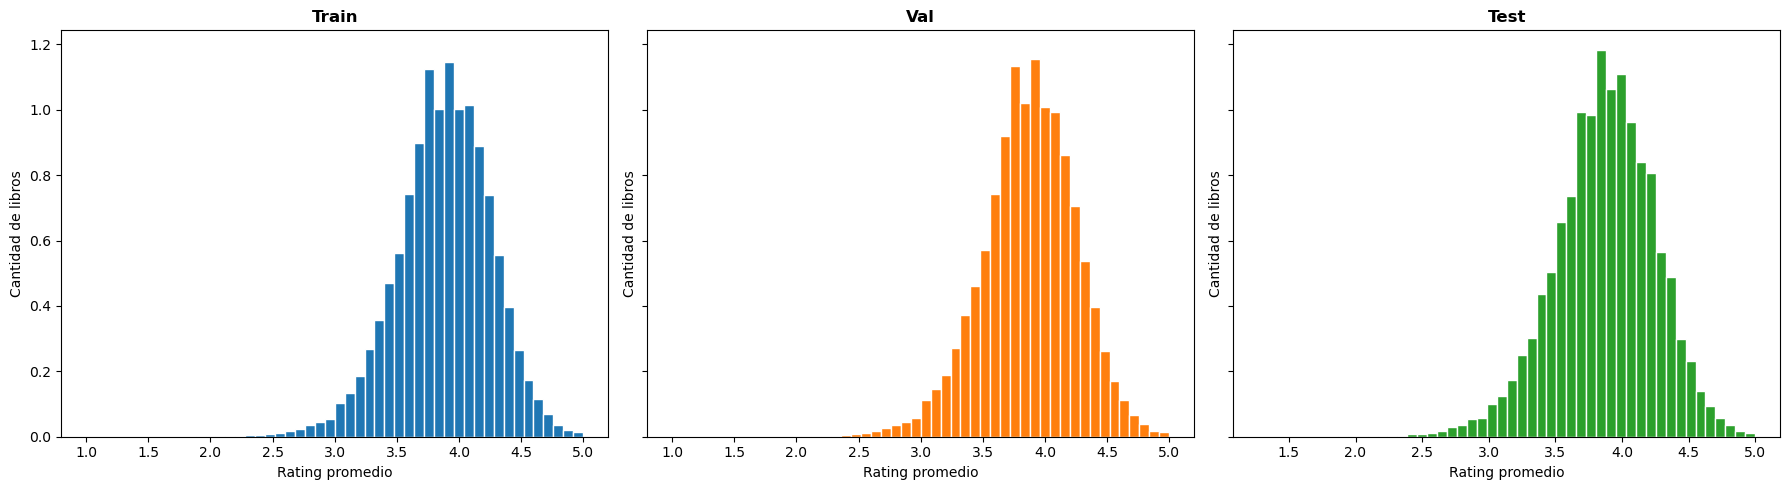

In [34]:
plot_ratings_subplots(df_train, df_val, df_test, normalize = True)


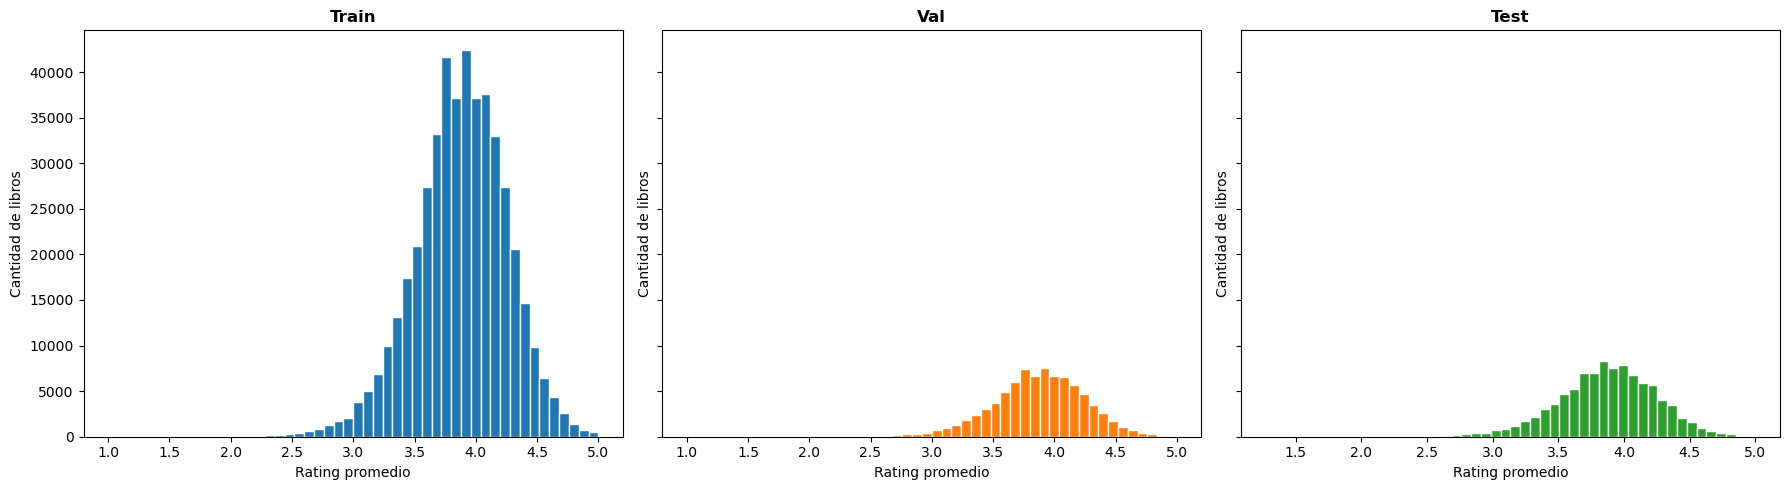

In [35]:
plot_ratings_subplots(df_train, df_val, df_test, normalize = False)

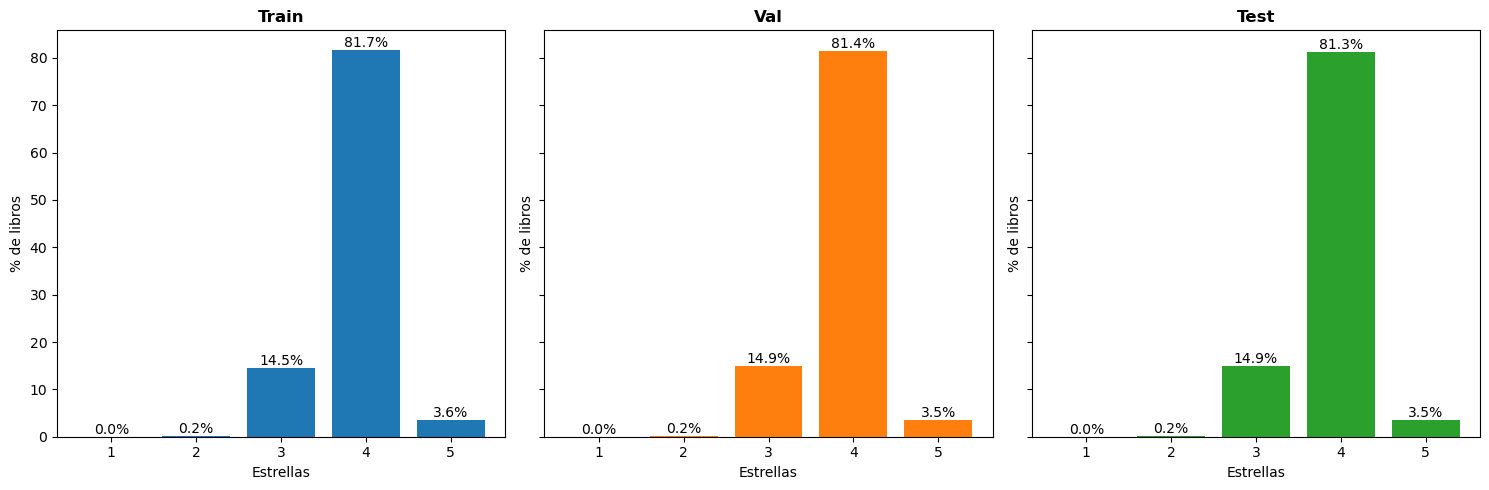

In [36]:
plot_stars_subplots(df_train, df_val, df_test)

Luego del preprocesamiento, notamos que ya no quedan libros con un rating de 0 estrellas. Muy probablemente eran libros con datos mal subidos, o habian muy pocos ratings como para que sea un resultado confiable. Para nuestro problema de clasificacion entonces vamos a tener 5 clases: 1 estrella, 2 estrellas, 3 estrellas 4 estrellas y 5 estrellas.